<h1>Extracting and Visualizing Stock Data</h1>
<h2>Description</h2>


Extracting essential data from a dataset and displaying it is a necessary part of data science; therefore individuals can make correct decisions based on the data. In this assignment, you will extract some stock data, you will then display this data in a graph.


<h2>Table of Contents</h2>
<div class="alert alert-block alert-info" style="margin-top: 20px">
    <ul>
        <li>Define a Function that Makes a Graph</li>
        <li>Question 1: Use yfinance to Extract Stock Data</li>
        <li>Question 2: Use Webscraping to Extract Tesla Revenue Data</li>
        <li>Question 3: Use yfinance to Extract Stock Data</li>
        <li>Question 4: Use Webscraping to Extract GME Revenue Data</li>
        <li>Question 5: Plot Tesla Stock Graph</li>
        <li>Question 6: Plot GameStop Stock Graph</li>
    </ul>
<p>
    Estimated Time Needed: <strong>30 min</strong></p>
</div>

<hr>


***Note***:- If you are working Locally using anaconda, please uncomment the following code and execute it.
Use the version as per your python version.


In [ ]:
!pip install yfinance
!pip install bs4
!pip install nbformat
!pip install matplotlib

In [ ]:
import yfinance as yf
import pandas as pd
import requests
from bs4 import BeautifulSoup

In Python, you can ignore warnings using the warnings module. You can use the filterwarnings function to filter or ignore specific warning messages or categories.


In [ ]:
import warnings
# Ignore all warnings
warnings.filterwarnings("ignore", category=FutureWarning)

## Define Graphing Function


In this section, we define the function `make_graph`. **You don't have to know how the function works, you should only care about the inputs. It takes a dataframe with stock data (dataframe must contain Date and Close columns), a dataframe with revenue data (dataframe must contain Date and Revenue columns), and the name of the stock.**


In [3]:
!pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 157.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 171.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 104.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.7/15.7 MB 195.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 161.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [matplotlib]8 [matplotlib]


In [14]:
# The make_graph function has been modified to use Matplotlib for static graphs. Earlier, it used Plotly to generate interactive dashboards, which caused issues when uploading the notebook in the MARK assignment submission.



import matplotlib.pyplot as plt

def make_graph(stock_data, revenue_data, stock):
    stock_data_specific = stock_data[stock_data.Date <= '2021-06-14']
    revenue_data_specific = revenue_data[revenue_data.Date <= '2021-04-30']

    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

    # Stock price
    axes[0].plot(pd.to_datetime(stock_data_specific.Date), stock_data_specific.Close.astype("float"), label="Share Price", color="blue")
    axes[0].set_ylabel("Price ($US)")
    axes[0].set_title(f"{stock} - Historical Share Price")

    # Revenue
    axes[1].plot(pd.to_datetime(revenue_data_specific.Date), revenue_data_specific.Revenue.astype("float"), label="Revenue", color="green")
    axes[1].set_ylabel("Revenue ($US Millions)")
    axes[1].set_xlabel("Date")
    axes[1].set_title(f"{stock} - Historical Revenue")

    plt.tight_layout()
    plt.show()

In [13]:
!pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 35.4 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 155.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 60.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 148.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]


Use the make_graph function that we’ve already defined. You’ll need to invoke it in questions 5 and 6 to display the graphs and create the dashboard. 
> **Note: You don’t need to redefine the function for plotting graphs anywhere else in this notebook; just use the existing function.**


## Question 1: Use yfinance to Extract Stock Data


Using the `Ticker` function enter the ticker symbol of the stock we want to extract data on to create a ticker object. The stock is Tesla and its ticker symbol is `TSLA`.


In [2]:
%pip install yfinance

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 129.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 159.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 181.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 140.4 MB/s eta 0:00:00
  Attempting uninstall: cffi╺━━━━━━━━━━━━━━━━━━━━━━━  4/10 [lxml]]]f]
    Found existing installation: cffi 1.17.1━━━━━━━━━━━━━━━━━━  4/10 [lxml]
    Uninstalling cffi-1.17.1:╺━━━━━━━━━━━━━━━━━━━━━━━  4/10 [lxml]
      Successfully uninstalled cffi-1.17.1━━━━━━━━━━━━━━━━━━━  5/10 [cffi]
  Attempting uninstall: certifim╺━━━━━━━━━━━━━━━━━━━  5/10 [cffi]
    Found existing installation: certifi 2025.1.31━━━━━━━━━━━━  5/10 [cffi]
    Uninstalling certifi-2025.1.31:━━━━━━━━━━━━━━━━━━━  5/10 [cffi]
      Successfully uninstalled certifi-2025.1.31━━━━━━━━━━━━━━  5/10 [cffi]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [yfinance]/10 [yfinance]]
Note: you may need to restart th

In [3]:

import yfinance as yf 

tesla = yf.Ticker("TSLA") 

print("tesla ticker created successfully!")

tesla ticker created successfully!


Using the ticker object and the function `history` extract stock information and save it in a dataframe named `tesla_data`. Set the `period` parameter to ` "max" ` so we get information for the maximum amount of time.


In [4]:
tesla_data = tesla.history(period="max") 

tesla_data.reset_index(inplace=True)

tesla_data.head()

/opt/conda/lib/python3.12/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/opt/conda/lib/python3.12/site-packages/yfinance/utils.py:604: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  splits.set_index("date", inplace=True)
/opt/conda/lib/python3.12/site-packages/yfinance/utils.py:606: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  splits.sort_index(inplace=True)
/opt/conda/lib/python3.12/site-packag

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


**Reset the index** using the `reset_index(inplace=True)` function on the tesla_data DataFrame and display the first five rows of the `tesla_data` dataframe using the `head` function. Take a screenshot of the results and code from the beginning of Question 1 to the results below.


In [5]:
tesla_data.reset_index(inplace=True)

tesla_data.head()

/tmp/ipykernel_302/1936172285.py:1: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  tesla_data.reset_index(inplace=True)


,index,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,0,2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,1,2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2,2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,3,2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,4,2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


## Question 2: Use Webscraping to Extract Tesla Revenue Data


Use the `requests` library to download the webpage https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm Save the text of the response as a variable named `html_data`.


In [13]:
import requests 

url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm" 

html_data = requests.get(url).text 

print("Status code:", requests.get(url).status_code) 

Status code: 200


Parse the html data using `beautiful_soup` using parser i.e `html5lib` or `html.parser`.


In [1]:
%pip install --upgrade beautifulSoup4 

Note: you may need to restart the kernel to use updated packages.


In [14]:
 from bs4 import BeautifulSoup

 soup = BeautifulSoup(html_data, "html.parser") 

 print("Number of tables found:", len(soup.find_all("tbody")))

Number of tables found: 6


In [3]:
!pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 158.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.7/15.7 MB 165.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pandas]2m1/2 [pandas]


In [4]:
import pandas as pd 

print("pandas installed successfully!")

pandas installed successfully!


In [5]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

In [6]:
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm"

html_data = requests.get(url).text

Using `BeautifulSoup` or the `read_html` function extract the table with `Tesla Revenue` and store it into a dataframe named `tesla_revenue`. The dataframe should have columns `Date` and `Revenue`.


In [8]:
soup = BeautifulSoup(html_data,"html.parser")

In [10]:
html_tables = soup.find_all("tbody")

print("Number of tables found:",len(html_tables))

Number of tables found: 6


In [11]:
print(html_tables[0].find("tr"))

<tr>
<td style="text-align:center">2021</td>
<td style="text-align:center">$53,823</td>
</tr>


In [13]:
for row in html_tables[0].find_all("tr"):
    print(row.text.strip())

2021
$53,823
2020
$31,536
2019
$24,578
2018
$21,461
2017
$11,759
2016
$7,000
2015
$4,046
2014
$3,198
2013
$2,013
2012
$413
2011
$204
2010
$117
2009
$112


In [14]:
for row in html_tables[1].find_all("tr"):
    print(row.text.strip())

2022-09-30
$21,454
2022-06-30
$16,934
2022-03-31
$18,756
2021-12-31
$17,719
2021-09-30
$13,757
2021-06-30
$11,958
2021-03-31
$10,389
2020-12-31
$10,744
2020-09-30
$8,771
2020-06-30
$6,036
2020-03-31
$5,985
2019-12-31
$7,384
2019-09-30
$6,303
2019-06-30
$6,350
2019-03-31
$4,541
2018-12-31
$7,226
2018-09-30
$6,824
2018-06-30
$4,002
2018-03-31
$3,409
2017-12-31
$3,288
2017-09-30
$2,985
2017-06-30
$2,790
2017-03-31
$2,696
2016-12-31
$2,285
2016-09-30
$2,298
2016-06-30
$1,270
2016-03-31
$1,147
2015-12-31
$1,214
2015-09-30
$937
2015-06-30
$955
2015-03-31
$940
2014-12-31
$957
2014-09-30
$852
2014-06-30
$769
2014-03-31
$621
2013-12-31
$615
2013-09-30
$431
2013-06-30
$405
2013-03-31
$562
2012-12-31
$306
2012-09-30
$50
2012-06-30
$27
2012-03-31
$30
2011-12-31
$39
2011-09-30
$58
2011-06-30
$58
2011-03-31
$49
2010-12-31
$36
2010-09-30
$31
2010-06-30
$28
2010-03-31
$21
2009-12-31
2009-09-30
$46
2009-06-30
$27


In [27]:
tesla_revenue = pd.DataFrame(columns=["Date", "Revenue"])

for row in html_tables[1].find_all("tr"):
    col = row.find_all("td")

    if len(col) == 2:
        date = col[0].text.strip()
        revenue = col[1].text.strip()

        tesla_revenue = pd.concat([tesla_revenue,pd.DataFrame({"Date":[date],"Revenue":[revenue]})], ignore_index=True)

In [19]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

In [20]:
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm"

html_data = requests.get(url).text

In [21]:
soup = BeautifulSoup(html_data,"html.parser")
html_tables = soup.find_all("tbody")

In [22]:
len(html_tables)

6

In [24]:
tesla_revenue = pd.DataFrame(columns=["Date","Revenue"])

for row in html_tables[1].find_all("tr"):
    col = row.find_all("td")
    if len(col) == 2:
        date = col[0].text.strip()
        revenue = col[1].text.strip()
        tesla_revenue.loc[len(tesla_revenue)] = [date, revenue]

In [16]:
tesla_revenue.head()

,Date,Revenue
0,2022-09-30,"$21,454"
1,2022-06-30,"$16,934"
2,2022-03-31,"$18,756"
3,2021-12-31,"$17,719"
4,2021-09-30,"$13,757"


In [25]:
tesla_revenue["Revenue"] = tesla_revenue["Revenue"].str.replace(',|\$','',regex=True)

In [26]:
tesla_revenue.tail()

,Date,Revenue
49,2010-06-30,28
50,2010-03-31,21
51,2009-12-31,
52,2009-09-30,46
53,2009-06-30,27


<details><summary>Step-by-step instructions</summary>

```

Here are the step-by-step instructions:

1. Create an Empty DataFrame
2. Find the Relevant Table
3. Check for the Tesla Quarterly Revenue Table
4. Iterate Through Rows in the Table Body
5. Extract Data from Columns
6. Append Data to the DataFrame

```
</details>


<details><summary>Click here if you need help locating the table</summary>

```
    
Below is the code to isolate the table, you will now need to loop through the rows and columns like in the previous lab
    
soup.find_all("tbody")[1]
    
If you want to use the read_html function the table is located at index 1

We are focusing on quarterly revenue in the lab.
```

</details>


Execute the following line to remove the comma and dollar sign from the `Revenue` column. 


In [17]:

tesla_revenue["Revenue"] = tesla_revenue["Revenue"].str.replace(',|\$', '', regex = True)

Execute the following lines to remove an null or empty strings in the Revenue column.


In [18]:
tesla_revenue.dropna(inplace=True)

/tmp/ipykernel_301/442481140.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  tesla_revenue.dropna(inplace=True)


Display the last 5 row of the `tesla_revenue` dataframe using the `tail` function. Take a screenshot of the results.


In [19]:


tesla_revenue.tail()


,Date,Revenue
49,2010-06-30,28
50,2010-03-31,21
51,2009-12-31,
52,2009-09-30,46
53,2009-06-30,27


## Question 3: Use yfinance to Extract Stock Data


Using the `Ticker` function enter the ticker symbol of the stock we want to extract data on to create a ticker object. The stock is GameStop and its ticker symbol is `GME`.


In [2]:
!pip install yfinance

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 92.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 78.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.7/15.7 MB 134.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 131.1 MB/s eta 0:00:00
  Attempting uninstall: cffi0m╺━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/9 [lxml]]]
    Found existing installation: cffi 1.17.1━━━━━━━━━━━━━━━━━━ 3/9 [lxml]
    Uninstalling cffi-1.17.1:0m━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/9 [lxml]
      Successfully uninstalled cffi-1.17.10m━━━━━━━━━━━━━━━━━━━━━━ 4/9 [cffi]
  Attempting uninstall: certifi91m╸━━━━━━━━━━━━━━━━━━━━━━ 4/9 [cffi]
    Found existing installation: certifi 2025.1.31━━━━━━━━━━━━ 4/9 [cffi]
    Uninstalling certifi-2025.1.31:━━━━━━━━━━━━━━━━━━━━━━ 4/9 [cffi]
      Successfully uninstalled certifi-2025.1.31━━━━━━━━━━━━━━ 4/9 [cffi]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [yfinance]8/9 [yfinance]]


In [3]:
import yfinance as yf 

print("YFinance installed successfully!")

YFinance installed successfully!


Using the ticker object and the function `history` extract stock information and save it in a dataframe named `gme_data`. Set the `period` parameter to ` "max" ` so we get information for the maximum amount of time.


In [6]:
gme_data = gme.history(period="max")

In [4]:
gme = yf.Ticker("GME")

In [7]:
gme_data.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2002-02-13 00:00:00-05:00,1.620129,1.693350,1.603296,1.691667,76216000,0.0,0.0
2002-02-14 00:00:00-05:00,1.712707,1.716074,1.670626,1.683250,11021600,0.0,0.0
2002-02-15 00:00:00-05:00,1.683250,1.687458,1.658002,1.674834,8389600,0.0,0.0
2002-02-19 00:00:00-05:00,1.666418,1.666418,1.578047,1.607504,7410400,0.0,0.0
2002-02-20 00:00:00-05:00,1.615920,1.662210,1.603296,1.662210,6892800,0.0,0.0


**Reset the index** using the `reset_index(inplace=True)` function on the gme_data DataFrame and display the first five rows of the `gme_data` dataframe using the `head` function. Take a screenshot of the results and code from the beginning of Question 3 to the results below.


In [8]:
gme_data.reset_index(inplace=True)

/tmp/ipykernel_301/261389486.py:1: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  gme_data.reset_index(inplace=True)


In [9]:
gme_data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2002-02-13 00:00:00-05:00,1.620129,1.693350,1.603296,1.691667,76216000,0.0,0.0
1,2002-02-14 00:00:00-05:00,1.712707,1.716074,1.670626,1.683250,11021600,0.0,0.0
2,2002-02-15 00:00:00-05:00,1.683250,1.687458,1.658002,1.674834,8389600,0.0,0.0
3,2002-02-19 00:00:00-05:00,1.666418,1.666418,1.578047,1.607504,7410400,0.0,0.0
4,2002-02-20 00:00:00-05:00,1.615920,1.662210,1.603296,1.662210,6892800,0.0,0.0


## Question 4: Use Webscraping to Extract GME Revenue Data


Use the `requests` library to download the webpage https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html. Save the text of the response as a variable named `html_data_2`


In [11]:
import requests

In [12]:
url_2 = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html"

html_data_2 = requests.get(url_2).text

Parse the html data using `beautiful_soup` using parser i.e `html5lib` or `html.parser`.


In [14]:
import requests
from bs4 import BeautifulSoup

In [15]:
soup_2 = BeautifulSoup(html_data_2,"html.parser")

Using `BeautifulSoup` or the `read_html` function extract the table with `GameStop Revenue` and store it into a dataframe named `gme_revenue`. The dataframe should have columns `Date` and `Revenue`. Make sure the comma and dollar sign is removed from the `Revenue` column.


> **Note: Use the method similar to what you did in question 2.**  


<details><summary>Click here if you need help locating the table</summary>

```
    
Below is the code to isolate the table, you will now need to loop through the rows and columns like in the previous lab
    
soup.find_all("tbody")[1]
    
If you want to use the read_html function the table is located at index 1


```

</details>


In [18]:
url_2 = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html"

html_data_2 = requests.get(url_2).text

In [19]:
soup_2 = BeautifulSoup(html_data_2,"html.parser")

In [20]:
html_tables_2 = soup_2.find_all("tbody")

print("Number of tables found:", len(html_tables_2))

Number of tables found: 6


In [24]:
html_tables_2 = soup_2.find_all("tbody")

print(len(html_tables_2))

6


In [25]:
for row in html_tables_2[1].find_all("tr"):
    print(row.text.strip())

2020-04-30
$1,021
2020-01-31
$2,194
2019-10-31
$1,439
2019-07-31
$1,286
2019-04-30
$1,548
2019-01-31
$3,063
2018-10-31
$1,935
2018-07-31
$1,501
2018-04-30
$1,786
2018-01-31
$2,825
2017-10-31
$1,989
2017-07-31
$1,688
2017-04-30
$2,046
2017-01-31
$2,403
2016-10-31
$1,959
2016-07-31
$1,632
2016-04-30
$1,972
2016-01-31
$3,525
2015-10-31
$2,016
2015-07-31
$1,762
2015-04-30
$2,061
2015-01-31
$3,476
2014-10-31
$2,092
2014-07-31
$1,731
2014-04-30
$1,996
2014-01-31
$3,684
2013-10-31
$2,107
2013-07-31
$1,384
2013-04-30
$1,865
2013-01-31
$3,562
2012-10-31
$1,773
2012-07-31
$1,550
2012-04-30
$2,002
2012-01-31
$3,579
2011-10-31
$1,947
2011-07-31
$1,744
2011-04-30
$2,281
2011-01-31
$3,693
2010-10-31
$1,899
2010-07-31
$1,799
2010-04-30
$2,083
2010-01-31
$3,524
2009-10-31
$1,835
2009-07-31
$1,739
2009-04-30
$1,981
2009-01-31
$3,492
2008-10-31
$1,696
2008-07-31
$1,804
2008-04-30
$1,814
2008-01-31
$2,866
2007-10-31
$1,611
2007-07-31
$1,338
2007-04-30
$1,279
2007-01-31
$2,304
2006-10-31
$1,012
2006-07-31

In [22]:
import pandas as pd

In [26]:
gme_revenue = pd.DataFrame(columns=["Date","Revenue"])

for row in html_tables_2[1].find_all("tr"):
    col = row.find_all("td")

    if len(col) == 2:
        date = col[0].text.strip()
        revenue = col[1].text.strip()

        gme_revenue = pd.concat([gme_revenue,pd.DataFrame({"Date":[date],"Revenue":[revenue]})], ignore_index=True)

Remove the comma and dollar sign, an null or empty strings from the Revenue column.


In [27]:
gme_revenue["Revenue"] = gme_revenue["Revenue"].str.replace(',|\$', '', regex=True)

Display the last five rows of the `gme_revenue` dataframe using the `tail` function. Take a screenshot of the results.


In [28]:
gme_revenue.tail()

,Date,Revenue
57,2006-01-31,1667
58,2005-10-31,534
59,2005-07-31,416
60,2005-04-30,475
61,2005-01-31,709


## Question 5: Plot Tesla Stock Graph


Use the `make_graph` function to graph the Tesla Stock Data, also provide a title for the graph. Note the graph will only show data upto June 2021.


<details><summary>Hint</summary>

```

You just need to invoke the make_graph function with the required parameter to print the graphs.The structure to call the `make_graph` function is `make_graph(tesla_data, tesla_revenue, 'Tesla')`.

```
    
</details>


In [9]:
!pip install yfinance

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 153.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 149.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 180.4 MB/s eta 0:00:00
  Attempting uninstall: cffi━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/8 [lxml]e]
    Found existing installation: cffi 1.17.1━━━━━━━━━━━━━━━━━━ 2/8 [lxml]
    Uninstalling cffi-1.17.1:━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/8 [lxml]
      Successfully uninstalled cffi-1.17.1━━━━━━━━━━━━━━━━━━━━━━━━ 3/8 [cffi]
  Attempting uninstall: certifi0m━━━━━━━━━━━━━━━━━━━━━━━━ 3/8 [cffi]
    Found existing installation: certifi 2025.1.31━━━━━━━━━━━━━━━━ 4/8 [certifi]
    Uninstalling certifi-2025.1.31:━━━━━━━━━━━━━━━━━━━ 4/8 [certifi]
      Successfully uninstalled certifi-2025.1.31━━━━━━━━━━━━━━ 4/8 [certifi]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [yfinance]6/8 [curl_cffi]


In [10]:
import yfinance as yf

In [11]:
tesla = yf.Ticker("TSLA")
tesla_data = tesla.history(period='max')

In [12]:
tesla_data.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


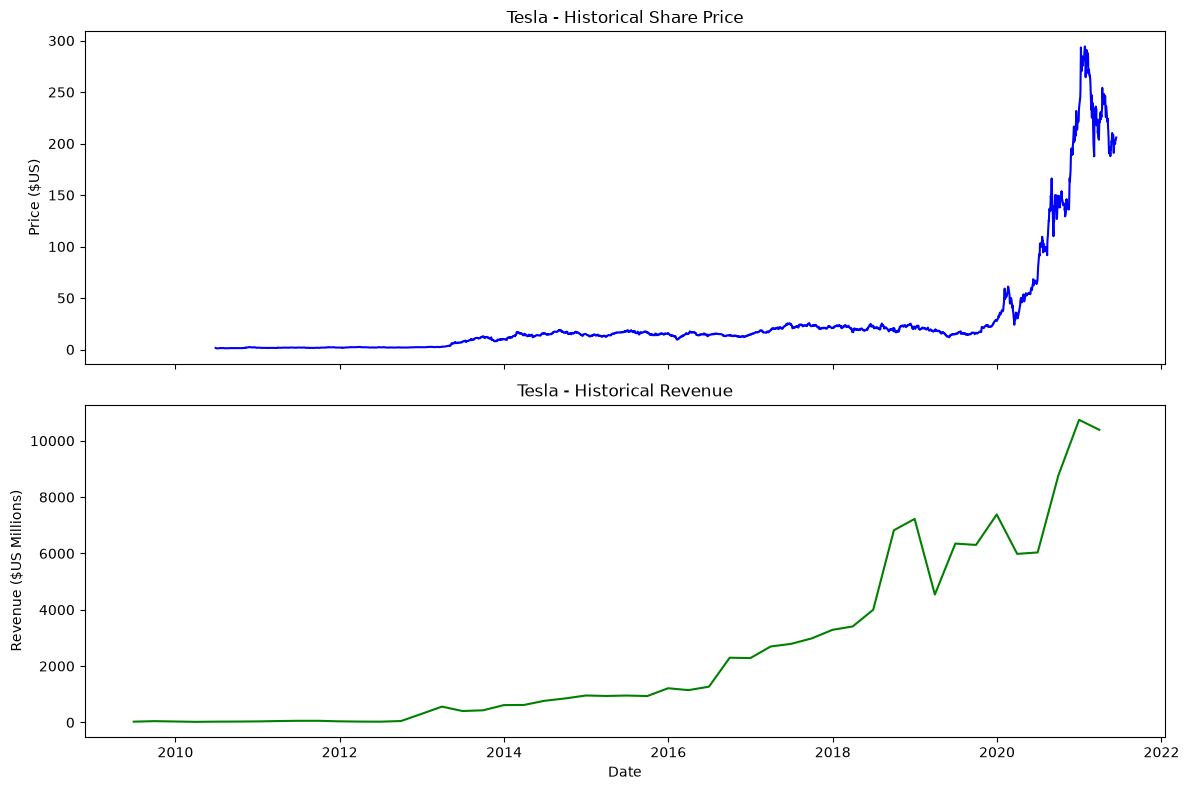

In [19]:
make_graph(tesla_data, tesla_revenue, 'Tesla')

In [18]:
import yfinance as yf

tesla = yf.Ticker("TSLA") 
tesla_data = tesla.history(period="max")

tesla_data.reset_index(inplace=True)

tesla_data.head()

/tmp/ipykernel_302/3113339821.py:6: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  tesla_data.reset_index(inplace=True)


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


In [17]:
!pip install yfinance

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 98.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 142.9 MB/s eta 0:00:00
  Attempting uninstall: cffi╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/7 [lxml]e]
    Found existing installation: cffi 1.17.1━━━━━━━━━━━━━━━━━━ 2/7 [lxml]
    Uninstalling cffi-1.17.1:━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/7 [lxml]
      Successfully uninstalled cffi-1.17.10m━━━━━━━━━━━━━━━━━━━━━━ 3/7 [cffi]
  Attempting uninstall: certifi90m╺━━━━━━━━━━━━━━━━━━━━━━ 3/7 [cffi]
    Found existing installation: certifi 2025.1.31━━━━━━━━━━━━ 3/7 [cffi]
    Uninstalling certifi-2025.1.31:━━━━━━━━━━━━━━━━━━━━━━ 3/7 [cffi]
      Successfully uninstalled certifi-2025.1.31━━━━━━━━━━━━━━ 3/7 [cffi]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [yfinance]6/7 [yfinance]]


In [29]:
tesla_data.reset_index(inplace=True)

/tmp/ipykernel_300/2002871923.py:1: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  tesla_data.reset_index(inplace=True)


In [31]:
tesla_data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


In [8]:
tesla_revenue.tail()

,Date,Revenue
49,2010-06-30,$28
50,2010-03-31,$21
51,2009-12-31,
52,2009-09-30,$46
53,2009-06-30,$27


In [9]:
tesla_revenue["Revenue"] = tesla_revenue["Revenue"].str.replace(r'[$,]','',regex=True).str.strip()

tesla_revenue["Revenue"] = pd.to_numeric(tesla_revenue["Revenue"],errors="coerce")

tesla_revenue.dropna(subset=["Revenue"], inplace=True)

tesla_revenue.tail()

/tmp/ipykernel_302/572339501.py:5: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  tesla_revenue.dropna(subset=["Revenue"], inplace=True)


,Date,Revenue
48,2010-09-30,31.0
49,2010-06-30,28.0
50,2010-03-31,21.0
52,2009-09-30,46.0
53,2009-06-30,27.0


In [34]:
tesla_revenue["Revenue"] = pd.to_numeric(tesla_revenue["Revenue"], errors="coerce")

In [37]:
tesla_revenue["Revenue"] = tesla_revenue["Revenue"].astype(str).str.replace(r'[$,]','',regex=True).str.strip()

In [39]:
tesla_revenue["Revenue"] = pd.to_numeric(tesla_revenue["Revenue"],errors="coerce")
tesla_revenue.dropna(subset=["Revenue"], inplace=True)
tesla_revenue.tail()

/tmp/ipykernel_300/580049305.py:2: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  tesla_revenue.dropna(subset=["Revenue"], inplace=True)


,Date,Revenue


In [7]:
print(len(html_tables))
print(html_tables[1].find_all("tr")[:3])

6
[<tr>
<td style="text-align:center">2022-09-30</td>
<td style="text-align:center">$21,454</td>
</tr>, <tr>
<td style="text-align:center">2022-06-30</td>
<td style="text-align:center">$16,934</td>
</tr>, <tr>
<td style="text-align:center">2022-03-31</td>
<td style="text-align:center">$18,756</td>
</tr>]


In [5]:
import requests
from bs4 import BeautifulSoup
import pandas as pd 

url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm"

html_data = requests.get(url).text
soup = BeautifulSoup(html_data, "html.parser")
html_tables = soup.find_all("tbody")

print(len(html_tables))

6


In [6]:
tesla_revenue = pd. DataFrame(columns=["Date","Revenue"])

for row in html_tables[1].find_all("tr"):
    col = row.find_all("td")
    if len(col) == 2:
        tesla_revenue.loc[len(tesla_revenue)] = [col[0].text.strip(),col[1].text.strip()]
        tesla_revenue.tail()

In [3]:
!pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 66.2 MB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.7/15.7 MB 158.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pandas]2m1/2 [pandas]


## Question 6: Plot GameStop Stock Graph


Use the `make_graph` function to graph the GameStop Stock Data, also provide a title for the graph. The structure to call the `make_graph` function is `make_graph(gme_data, gme_revenue, 'GameStop')`. Note the graph will only show data upto June 2021.


<details><summary>Hint</summary>

```

You just need to invoke the make_graph function with the required parameter to print the graphs.The structure to call the `make_graph` function is `make_graph(gme_data, gme_revenue, 'GameStop')`

```
    
</details>


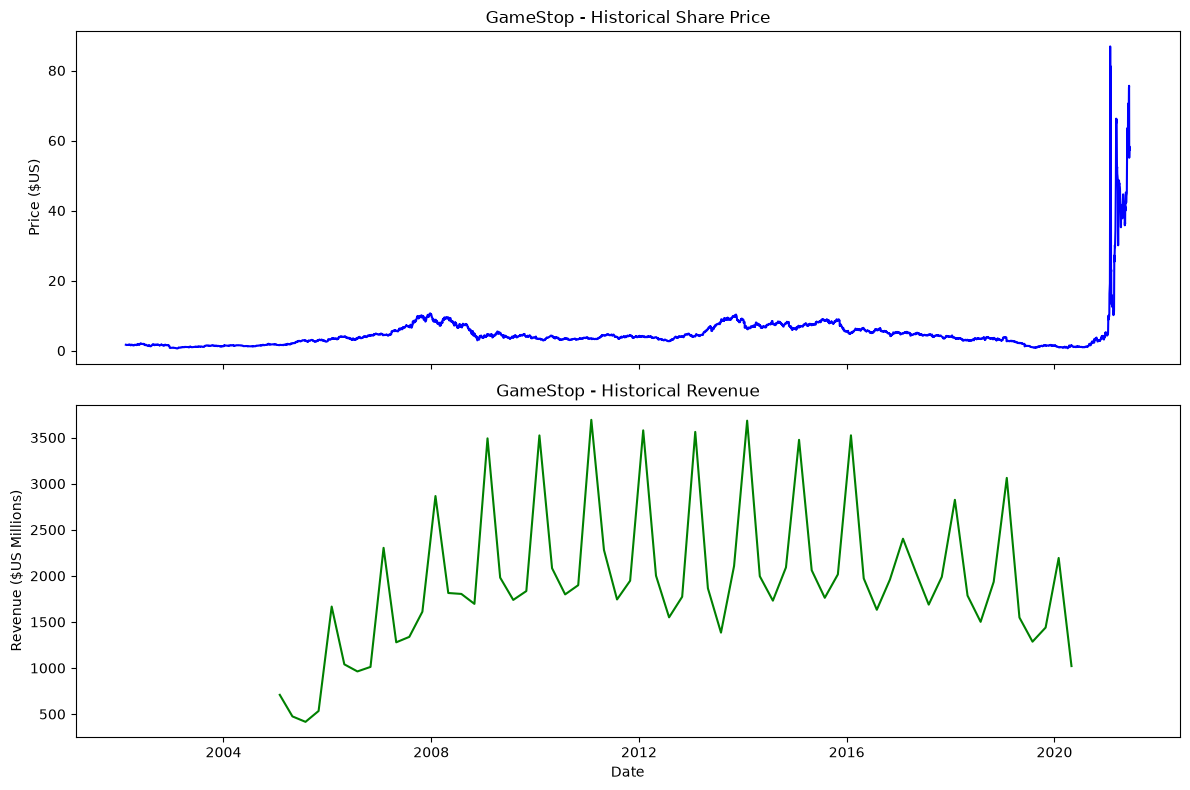

In [27]:
make_graph(gme_data, gme_revenue, 'GameStop')

In [21]:
import yfinance as yf 

gme = yf.Ticker("GME") 
gme_data = gme.history(period="max") 

gme_data.reset_index(inplace=True) 

gme_data.head()

/tmp/ipykernel_302/1807689889.py:6: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  gme_data.reset_index(inplace=True)


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2002-02-13 00:00:00-05:00,1.620129,1.693350,1.603296,1.691667,76216000,0.0,0.0
1,2002-02-14 00:00:00-05:00,1.712707,1.716074,1.670626,1.683251,11021600,0.0,0.0
2,2002-02-15 00:00:00-05:00,1.683250,1.687458,1.658002,1.674834,8389600,0.0,0.0
3,2002-02-19 00:00:00-05:00,1.666418,1.666418,1.578047,1.607504,7410400,0.0,0.0
4,2002-02-20 00:00:00-05:00,1.615920,1.662210,1.603296,1.662210,6892800,0.0,0.0


In [26]:
gme_revenue.tail()

,Date,Revenue
57,2006-01-31,1667
58,2005-10-31,534
59,2005-07-31,416
60,2005-04-30,475
61,2005-01-31,709


In [23]:
import requests 
from bs4 import BeautifulSoup 
import pandas as pd 

url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html" 

html_data_2 = requests.get(url).text 
soup_2 = BeautifulSoup(html_data_2, "html.parser") 
html_tables_2 = soup_2.find_all("tbody") 

print(len(html_tables_2))

6


In [24]:
gme_revenue = pd.DataFrame(columns=["Date", "Revenue"]) 

for row in html_tables_2[1].find_all("tr"): 
    col = row.find_all("td") 
    if len(col) == 2: 
        gme_revenue.loc[len(gme_revenue)] = [col[0].text.strip(),col[1].text.strip()] 

        gme_revenue.tail()

## Change Log

| Date (YYYY-MM-DD) | Version | Changed By    | Change Description        |
| ----------------- | ------- | ------------- | ------------------------- |
| 2022-02-28        | 1.2     | Lakshmi Holla | Changed the URL of GameStop |
| 2020-11-10        | 1.1     | Malika Singla | Deleted the Optional part |
| 2020-08-27        | 1.0     | Malika Singla | Added lab to GitLab       |

<hr>


In [25]:
gme_revenue["Revenue"] = gme_revenue["Revenue"].str.replace(r'[$,]','',regex=True).str.strip() 

gme_revenue["Revenue"] = pd.to_numeric(gme_revenue["Revenue"], errors = "coerce") 

gme_revenue.dropna(subset=["Revenue"], inplace=True) 

gme_revenue.tail()

/tmp/ipykernel_302/3026952878.py:5: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  gme_revenue.dropna(subset=["Revenue"], inplace=True)


,Date,Revenue
57,2006-01-31,1667
58,2005-10-31,534
59,2005-07-31,416
60,2005-04-30,475
61,2005-01-31,709


<h2>About the Authors:</h2> 

<a href="https://www.linkedin.com/in/joseph-s-50398b136/">Joseph Santarcangelo</a> has a PhD in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD.

Azim Hirjani


Copyright © 2020 IBM Corporation. All rights reserved.
